# Prostate cancer

This notebook reproduces results of the prostate cancer model of
[Montagud et al. (eLife, 2022)](https://doi.org/10.7554/eLife.72626), on the [MaBoSS website](https://maboss.curie.fr).
It is adapted from the [pyMaBoSS tutorial](https://pymaboss.readthedocs.io/en/latest/notebooks/Reproducing_Prostate_Montagud.html).

The model describes the signaling pathways involved in prostate cancer. With 133 nodes, it is a large model:
it requires an executable of MaBoSS supporting more than 128 nodes, such as `MaBoSS_256n`, which is provided by
the conda package of pyMaBoSS. Without any mutation, it can be considered as a model of healthy prostate cells
(the wild type model). The model was then personalized to the data of patients and cell lines.

**Requirements:** [pyMaBoSS](https://pymaboss.readthedocs.io/), the files `Montagud2022_Prostate_Cancer.bnd` and
`Montagud2022_Prostate_Cancer.cfg`, and the folder `patient_models`, in the same folder as this notebook.

In [1]:
import os
import maboss
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

# Common style for the figures of the MaBoSS website notebooks
COLORS = ["#FF7F00", "#1F77B4", "#2CA02C", "#D62728", "#9467BD",
          "#8C564B", "#E377C2", "#17BECF", "#BCBD22", "#7F7F7F"]
mpl.rcParams.update({
    "figure.figsize": (7, 4),
    "figure.dpi": 100,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
    "axes.prop_cycle": mpl.cycler(color=COLORS),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "legend.frameon": False,
    "lines.linewidth": 2,
})

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    """Save a figure in the figures folder."""
    fig.savefig(os.path.join(FIG_DIR, name + ".png"))

def state_label(state):
    """Readable label for a MaBoSS state."""
    return "none active" if state == "<nil>" else state.replace(" -- ", ", ")

def pie(probas, ax, title=None, min_proba=0.01, labels=None):
    """Pie chart of a distribution; probabilities below min_proba are grouped as 'others'."""
    probas = pd.Series(probas).sort_values(ascending=False)
    small = probas[probas < min_proba]
    probas = probas[probas >= min_proba]
    if len(small) > 0:
        probas["others"] = small.sum()
    names = [labels.get(s, state_label(s)) if labels else state_label(s) for s in probas.index]
    colors = [COLORS[i % len(COLORS)] if s != "others" else "#D9D9D9" for i, s in enumerate(probas.index)]
    wedges, _ = ax.pie(probas.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={"linewidth": 1, "edgecolor": "white"})
    ax.legend(wedges, [f"{n} ({p:.1%})" for n, p in zip(names, probas.values)],
              loc="center left", bbox_to_anchor=(1, 0.5))
    ax.set_aspect("equal")
    if title:
        ax.set_title(title)

def set_refstate_all(sim, value=0):
    """Give a reference state to every node.

    With MaBoSS 2.6.6, the states of the stationary distributions only include the nodes
    having a reference state; this makes them include all the nodes, as in previous versions.
    """
    for node in sim.network:
        if node not in sim.refstate:
            sim.refstate[node] = value

ipylab module is not installed, menus and toolbar are disabled.


Final states are shown as stacked bars, with one color for each state, shared by all the figures.

In [2]:
STATE_COLORS = {}

def state_color(state):
    if state == "<nil>":
        return "#D9D9D9"
    if state not in STATE_COLORS:
        STATE_COLORS[state] = COLORS[len(STATE_COLORS) % len(COLORS)]
    return STATE_COLORS[state]

def final_states(results):
    """Final state distributions of several results, as a dataframe (one row per result)."""
    table = pd.concat([r.get_last_states_probtraj().set_axis([name]) for name, r in results.items()]).fillna(0)
    return table[table.sum().sort_values(ascending=False).index]

def plot_final_states(table, title, min_proba=0.01):
    """Stacked bars of final state distributions; small states are grouped as 'others'."""
    main = [s for s in table.columns if table[s].max() >= min_proba]
    table = table[main].assign(others=table.drop(columns=main).sum(axis=1))
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(table) + 1.5))
    left = np.zeros(len(table))
    for state in table.columns:
        color = "#F2F2F2" if state == "others" else state_color(state)
        ax.barh(table.index, table[state], left=left, color=color, edgecolor="white",
                label=state_label(state) if state != "<nil>" else "no phenotype")
        left += table[state].values
    ax.set_xlim(0, 1)
    ax.invert_yaxis()
    ax.set_xlabel("Probability")
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
    return fig

## The model

In [3]:
model = maboss.load("Montagud2022_Prostate_Cancer.bnd", "Montagud2022_Prostate_Cancer.cfg")
outputs = [n for n in model.network if not model.network[n].is_internal]
print(len(model.network), "nodes")
print("Output nodes:", ", ".join(outputs))

133 nodes
Output nodes: Apoptosis, Metastasis, Proliferation


## Default simulation

In the configuration file, the inputs of the model are random: the simulation explores all the combinations of
inputs, and thus all the possible phenotypes.

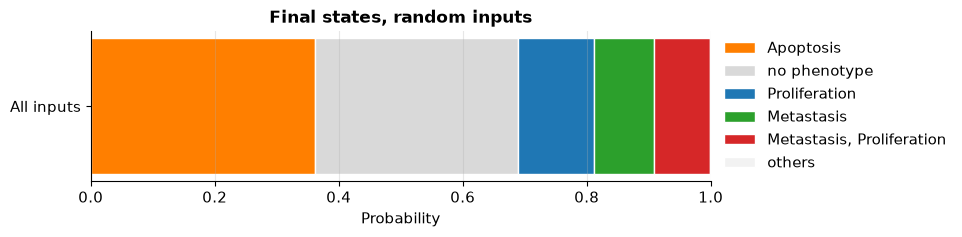

In [4]:
result_default = model.run()
fig = plot_final_states(final_states({"All inputs": result_default}), "Final states, random inputs")
save(fig, "prostate_default")

## Healthy cells

In the article, *"these healthy cells mostly exhibit quiescence (neither proliferation nor apoptosis) in the
absence of any input"* (Figure 3A). We set all the inputs to 0.

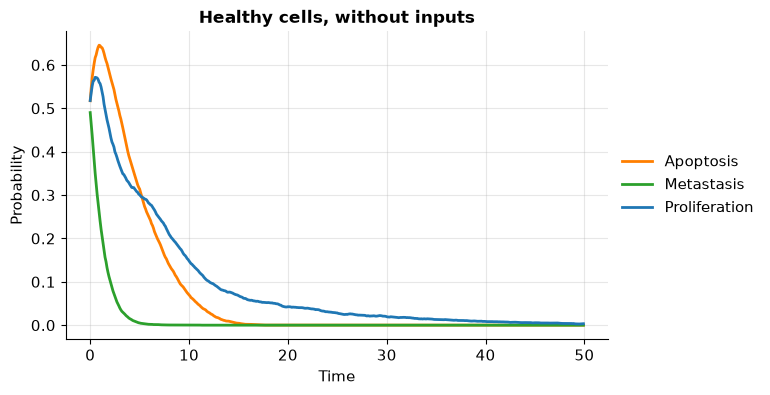

In [5]:
inputs = ["EGF", "FGF", "Androgen", "TGFb", "Hypoxia", "Nutrients", "Carcinogen", "fused_event", "Acidosis",
          "SPOP", "TNFalpha"]

model_healthy = model.copy()
for node in inputs:
    model_healthy.network.set_istate(node, [1, 0])
result_healthy = model_healthy.run()

nodes = result_healthy.get_nodes_probtraj()
fig, ax = plt.subplots()
for node in nodes.columns:
    ax.plot(nodes.index, nodes[node], label=node, color=state_color(node))
ax.set_xlabel("Time")
ax.set_ylabel("Probability")
ax.set_title("Healthy cells, without inputs")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5))
save(fig, "prostate_healthy")

## Growth condition and MYC_MAX inhibition

*"When Nutrients and growth factors (EGF or FGF) are present, Proliferation is activated"*. We activate EGF and
Nutrients, and simulate the inhibition of MYC_MAX, which blocks proliferation (Appendix 1, figure 34).

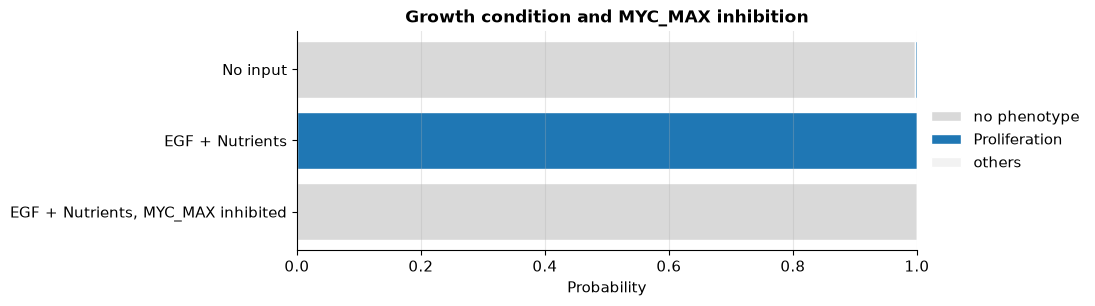

In [6]:
model_growth = model_healthy.copy()
model_growth.network.set_istate("EGF", [0, 1])
model_growth.network.set_istate("Nutrients", [0, 1])

model_growth_myc = model_growth.copy()
model_growth_myc.mutate("MYC_MAX", "OFF")

growth = final_states({
    "No input": result_healthy,
    "EGF + Nutrients": model_growth.run(),
    "EGF + Nutrients, MYC_MAX inhibited": model_growth_myc.run(),
})
fig = plot_final_states(growth, "Growth condition and MYC_MAX inhibition")
save(fig, "prostate_growth")

## Single mutants

To find other mutations that reduce or block proliferation, we simulate the inhibition of several candidate
nodes, in the growth condition, with the functions of `maboss.pipelines`.

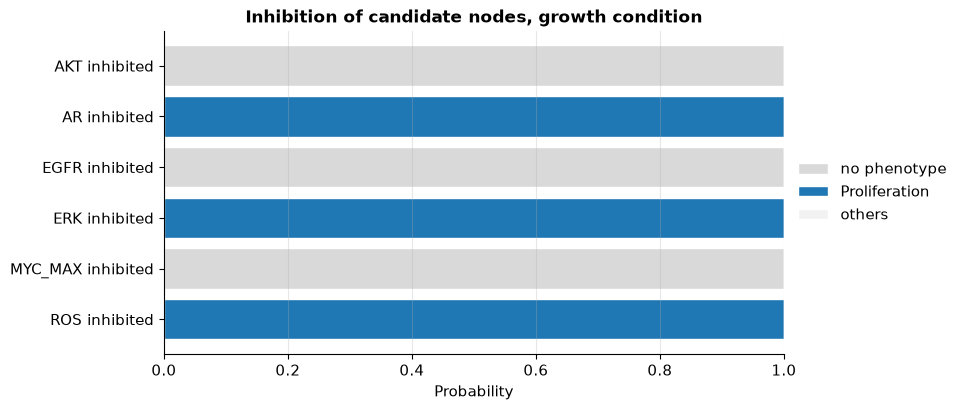

In [7]:
from maboss.pipelines import simulate_single_mutants, filter_sensitivity

candidates = ["AKT", "AR", "EGFR", "ERK", "MYC_MAX", "ROS"]
mutants = simulate_single_mutants(model_growth, candidates, "OFF")

# The results are indexed by (node, "OFF")
table = final_states({f"{node} inhibited": r for (node, _), r in mutants.items()})
fig = plot_final_states(table, "Inhibition of candidate nodes, growth condition")
save(fig, "prostate_mutants")

`filter_sensitivity` selects the mutants without any proliferation:

In [8]:
no_proliferation = filter_sensitivity(mutants, state="Proliferation", maximum=0)
print("Mutants without proliferation:", ", ".join(sorted(node for node, _ in no_proliferation)))

Mutants without proliferation: AKT, EGFR, MYC_MAX


## Personalized models

Montagud et al. personalized the model to the data of patients (TCGA) and cell lines. We use here ten of the
patient models, provided with the article. Their phenotypes vary a lot.

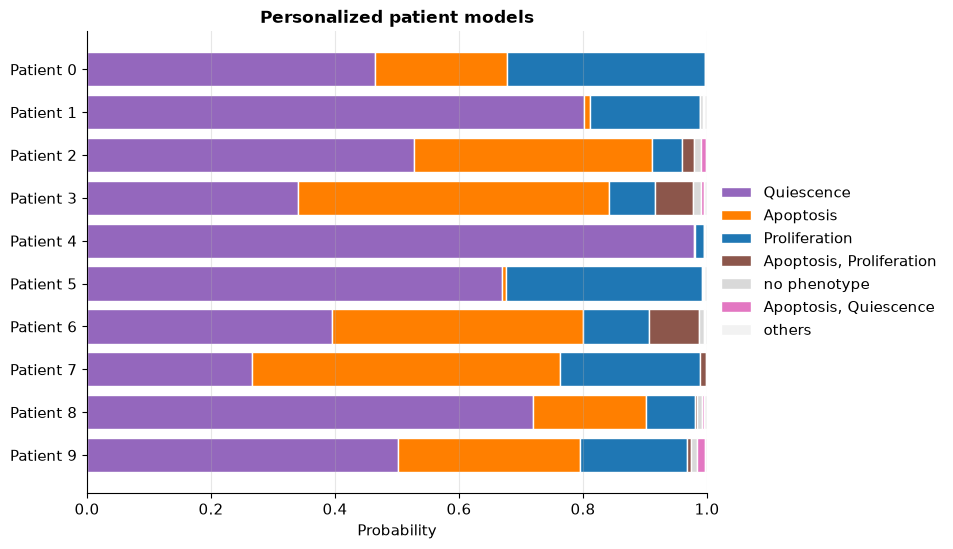

In [9]:
patients = {
    f"Patient {i}": maboss.load(f"patient_models/PC_20191219_TCGA_mutCNA_RNA_{i}.bnd",
                                f"patient_models/PC_20191219_TCGA_mutCNA_RNA_{i}.cfg")
    for i in range(10)
}
patients_states = final_states({name: m.run() for name, m in patients.items()})
fig = plot_final_states(patients_states, "Personalized patient models")
save(fig, "prostate_patients")

We now simulate the growth condition with an inhibition of MYC_MAX on each personalized model.

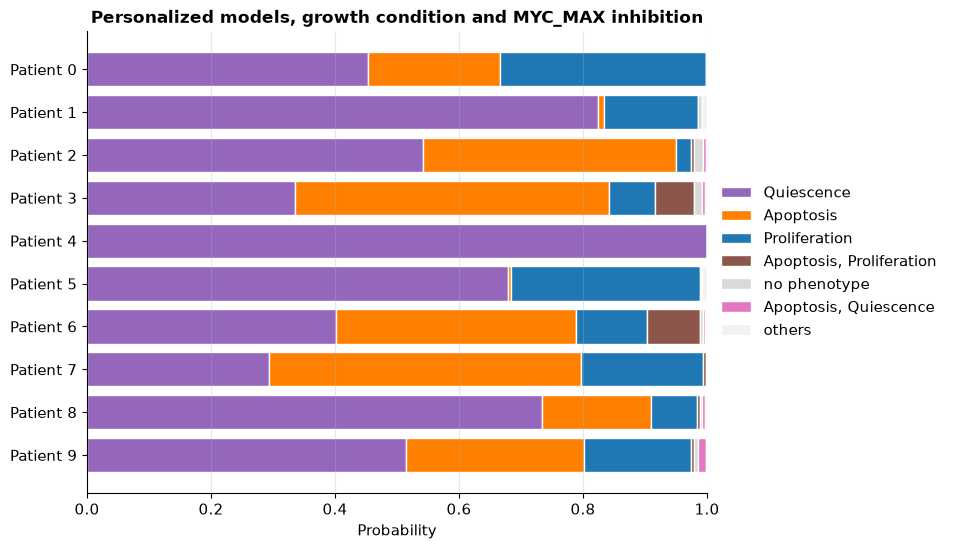

In [10]:
def growth_myc(patient_model):
    m = patient_model.copy()
    m.network.set_istate("EGF", [0, 1])
    m.network.set_istate("Nutrients", [0, 1])
    m.mutate("MYC_MAX", "OFF")
    return m.run()

patients_myc = final_states({name: growth_myc(m) for name, m in patients.items()})
fig = plot_final_states(patients_myc, "Personalized models, growth condition and MYC_MAX inhibition")
save(fig, "prostate_patients_myc")

The personalized models in which MYC_MAX inhibition reduces proliferation below 10%:

In [11]:
proliferation = patients_myc[[s for s in patients_myc.columns if "Proliferation" in s.split(" -- ")]].sum(axis=1)
proliferation[proliferation < 0.1].rename("Proliferation").to_frame()

,Proliferation
Patient 2,0.031572
Patient 4,0.000000
Patient 8,0.082875
